In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from evaluate_val import fit_models, evaluate_val
from evaluate_test import evaluate_test
from stacking_ensemble import fit_stacking_ensemble

os.environ["PYTHONHASHSEED"] = "42"
np.random.seed(42)
random.seed(42)
print("Seed: 42")

sns.set_theme(style="whitegrid", font="Segoe UI", rc={
    "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#E2E8F0",
})
DATASET_ORDER = ["data", "fe_data"]
MODEL_ORDER = ["KNN", "Decision Tree", "KMeans", "Gaussian Naive Bayes"]
DATASET_PALETTE = {"data": "#174EA6", "fe_data": "#B91C1C"}


Seed: 42


## Binary diagnosis aligned with the reference solution

Read the six CSVs in `splits`. Target **0 = no disease**, **1 = disease**. The baseline and FE representations share the same 80:10:10 split membership and numeric-then-categorical preprocessing order.

For standalone models, KNN searches **k=1..20** and Decision Tree searches **depth=2..5**. Both use shuffled **5-fold Stratified K-Fold**, seed 42, selecting the highest mean **accuracy**. KMeans matches the reference with `init="random"`, `n_init="auto"`; cluster labels are mapped using training labels only.

Stacking follows the reference independently of standalone tuning: base **KNN(k=5)**, **Decision Tree(max_depth=None)**, and **GaussianNB**, final **KNN(k=5)**, probabilities as meta-features, and **5-fold CV without shuffle**.

The prepared CSVs were preprocessed and MI-selected before CV, as in the reference. Validation/test are excluded from preprocessing fitting, MI selection, and model fitting.

In [2]:
SPLIT_DIR = Path("splits")
if not SPLIT_DIR.exists():
    SPLIT_DIR = Path("3.1_Project_Heart_Disease_Diagnosis/splits")

datasets = {}
summary_rows = []
for dataset_name, prefix in [("data", ""), ("fe_data", "fe_")]:
    parts = {}
    for split in ["train", "val", "test"]:
        frame = pd.read_csv(SPLIT_DIR / f"{prefix}{split}.csv")
        if frame.isna().any().any():
            raise ValueError(f"{dataset_name}/{split} contains missing values")
        if set(frame["target"].unique()) != {0, 1}:
            raise ValueError(f"{dataset_name}/{split}: expected binary target 0/1")
        parts[f"X_{split}"] = frame.drop(columns="target")
        parts[f"y_{split}"] = frame["target"].astype(int)
        summary_rows.append({
            "dataset": dataset_name, "split": split, "rows": len(frame),
            "features": frame.shape[1] - 1,
            "no_disease_0": int((frame["target"] == 0).sum()),
            "disease_1": int((frame["target"] == 1).sum()),
        })
    for split in ["val", "test"]:
        assert parts[f"X_{split}"].columns.equals(parts["X_train"].columns)
    datasets[dataset_name] = parts
for split in ["train", "val", "test"]:
    pd.testing.assert_series_equal(datasets["data"][f"y_{split}"],
                                   datasets["fe_data"][f"y_{split}"])
display(pd.DataFrame(summary_rows))


,dataset,split,rows,features,no_disease_0,disease_1
0,data,train,242,13,131,111
1,data,val,30,13,16,14
2,data,test,31,13,17,14
3,fe_data,train,242,13,131,111
4,fe_data,val,30,13,16,14
5,fe_data,test,31,13,17,14


## Train and select parameters
`evaluate_val.py` supplies `find_optimal_k`, `find_optimal_depth`, `fit_models`, and shared evaluation. Standalone KNN/DT use training-only CV accuracy. Their selected parameters are not reused by the reference stacking configuration.

In [3]:
fitted_models = {}
cv_results = {}
tuning_rows = []
for dataset_name in DATASET_ORDER:
    parts = datasets[dataset_name]
    models, best_params, cv_tables = fit_models(
        parts["X_train"], parts["y_train"], n_splits=5, random_state=42
    )
    fitted_models[dataset_name] = models
    cv_results[dataset_name] = cv_tables
    tuning_rows.append({
        "dataset": dataset_name, "best_k": best_params["k"],
        "best_depth": best_params["depth"],
        "knn_cv_accuracy": cv_tables["KNN"]["mean_accuracy"].max(),
        "dt_cv_accuracy": cv_tables["Decision Tree"]["mean_accuracy"].max(),
    })
tuning_summary = pd.DataFrame(tuning_rows)
display(tuning_summary.round(4))


,dataset,best_k,best_depth,knn_cv_accuracy,dt_cv_accuracy
0,data,11,3,0.7977,0.7728
1,fe_data,15,3,0.8387,0.7603


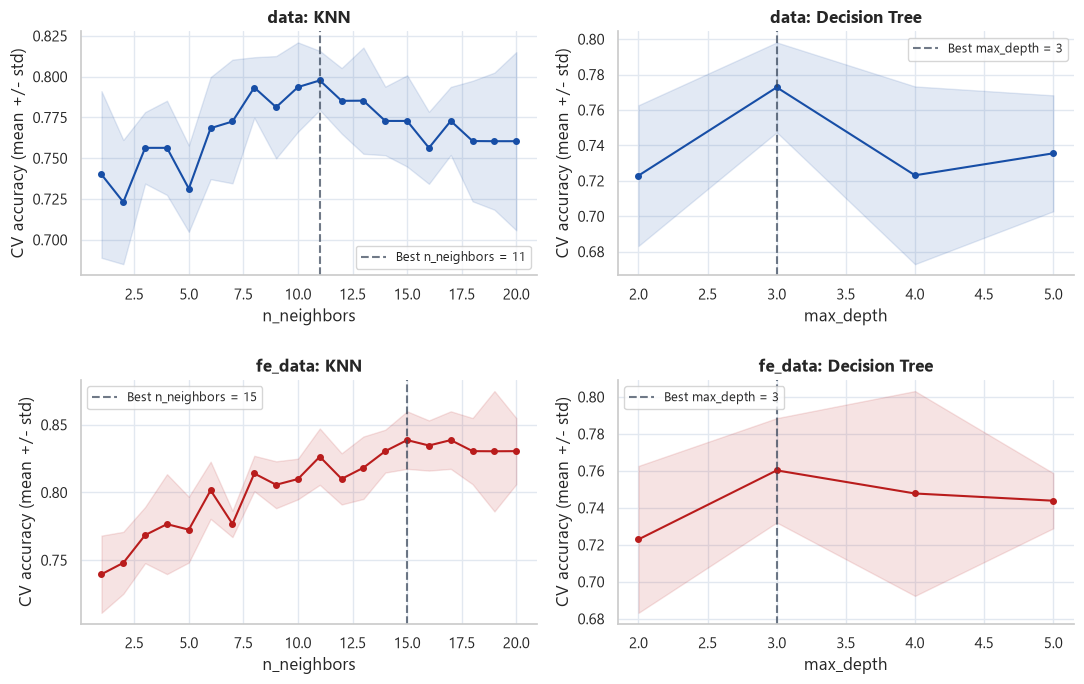

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, dataset_name in enumerate(DATASET_ORDER):
    for col, (model_name, parameter) in enumerate([
        ("KNN", "n_neighbors"), ("Decision Tree", "max_depth")
    ]):
        table = cv_results[dataset_name][model_name]
        x = table[parameter].to_numpy(dtype=float)
        mean = table["mean_accuracy"].to_numpy()
        std = table["std_accuracy"].to_numpy()
        ax = axes[row, col]
        ax.plot(x, mean, color=DATASET_PALETTE[dataset_name], marker="o", markersize=4)
        ax.fill_between(x, np.maximum(0, mean - std), np.minimum(1, mean + std),
                        color=DATASET_PALETTE[dataset_name], alpha=0.12)
        best_index = int(np.argmax(mean))
        ax.axvline(x[best_index], color="#334155", linestyle="--", alpha=0.7,
                   label=f"Best {parameter} = {int(x[best_index])}")
        ax.set_title(f"{dataset_name}: {model_name}")
        ax.set_xlabel(parameter)
        ax.set_ylabel("CV accuracy (mean +/- std)")
        ax.legend(fontsize=9)
fig.tight_layout(h_pad=2)
plt.show()


## Validation metrics
Precision, Recall, and F1 use macro averaging so both classes contribute equally. Models remain fitted on train; validation scores do not modify their parameters.

,dataset,split,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro
0,data,val,KNN,0.9000,0.9018,0.9000,0.9018,0.8999
1,data,val,Decision Tree,0.9333,0.9330,0.9330,0.9330,0.9330
2,data,val,KMeans,0.7000,0.6964,0.6991,0.6964,0.6970
3,data,val,Gaussian Naive Bayes,0.9000,0.9062,0.9118,0.9062,0.8999
4,fe_data,val,KNN,0.9000,0.9018,0.9000,0.9018,0.8999
5,fe_data,val,Decision Tree,0.9333,0.9330,0.9330,0.9330,0.9330
6,fe_data,val,KMeans,0.8000,0.7946,0.8056,0.7946,0.7964
7,fe_data,val,Gaussian Naive Bayes,0.9000,0.9062,0.9118,0.9062,0.8999


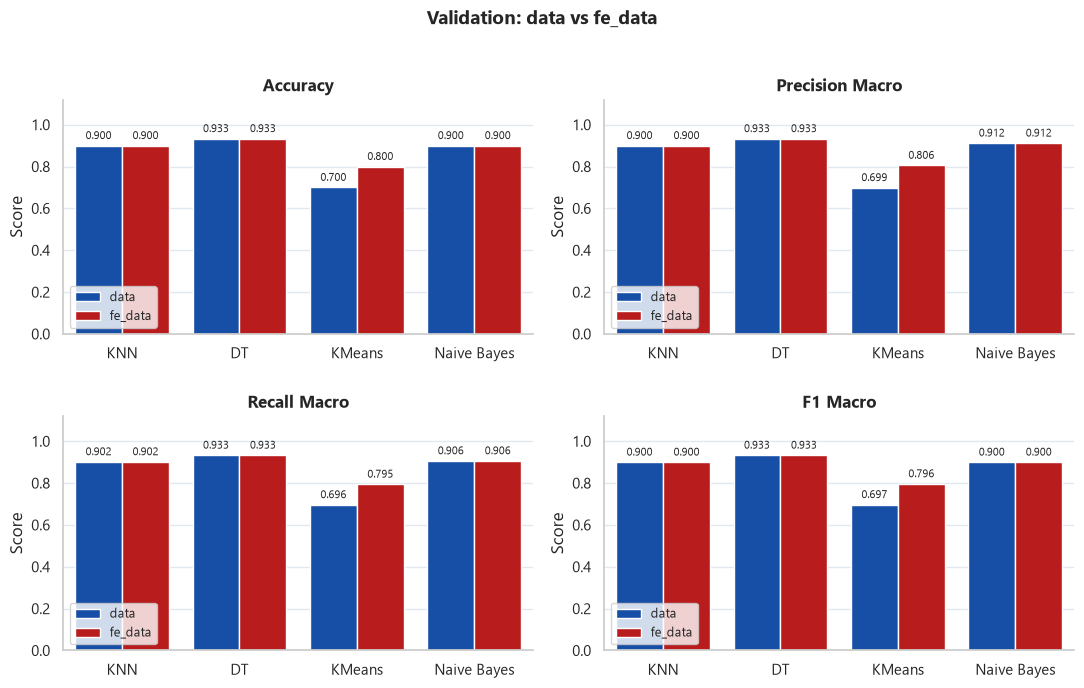

In [5]:
validation_results = {}
validation_frames = []
for dataset_name in DATASET_ORDER:
    parts = datasets[dataset_name]
    result = evaluate_val(fitted_models[dataset_name], parts["X_val"],
                          parts["y_val"], dataset=dataset_name)
    validation_results[dataset_name] = result
    validation_frames.append(result[0])
val_metrics = pd.concat(validation_frames, ignore_index=True)
display(val_metrics.round(4))


def plot_metric_comparison(metrics, title):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    for ax, metric in zip(axes.flat, ["accuracy", "precision_macro", "recall_macro", "f1_macro"]):
        sns.barplot(data=metrics, x="model", y=metric, hue="dataset",
                    order=MODEL_ORDER, hue_order=DATASET_ORDER,
                    palette=DATASET_PALETTE, saturation=1, errorbar=None, ax=ax)
        for container in ax.containers:
            ax.bar_label(container, fmt="%.3f", padding=3, fontsize=8)
        ax.set_ylim(0, 1.12)
        ax.set_title(metric.replace("_", " ").title())
        ax.set_xlabel("")
        ax.set_ylabel("Score")
        ax.set_xticks(range(len(MODEL_ORDER)), ["KNN", "DT", "KMeans", "Naive Bayes"])
        ax.legend(title="", fontsize=9)
        ax.grid(axis="x", visible=False)
    fig.suptitle(title, fontsize=14, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=2)
    plt.show()

plot_metric_comparison(val_metrics, "Validation: data vs fe_data")


## Test metrics
`evaluate_test.py` reuses the exact metric implementation from `evaluate_val.py`.
Evaluate the frozen train-fitted models once on test, without parameter search or refitting.

,dataset,split,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro
0,data,test,KNN,0.8387,0.8340,0.8397,0.8340,0.8360
1,data,test,Decision Tree,0.8065,0.8046,0.8046,0.8046,0.8046
2,data,test,KMeans,0.8710,0.8761,0.8729,0.8761,0.8708
3,data,test,Gaussian Naive Bayes,0.8387,0.8466,0.8466,0.8466,0.8387
4,fe_data,test,KNN,0.8387,0.8466,0.8466,0.8466,0.8387
5,fe_data,test,Decision Tree,0.8065,0.8046,0.8046,0.8046,0.8046
6,fe_data,test,KMeans,0.8710,0.8761,0.8729,0.8761,0.8708
7,fe_data,test,Gaussian Naive Bayes,0.8387,0.8466,0.8466,0.8466,0.8387


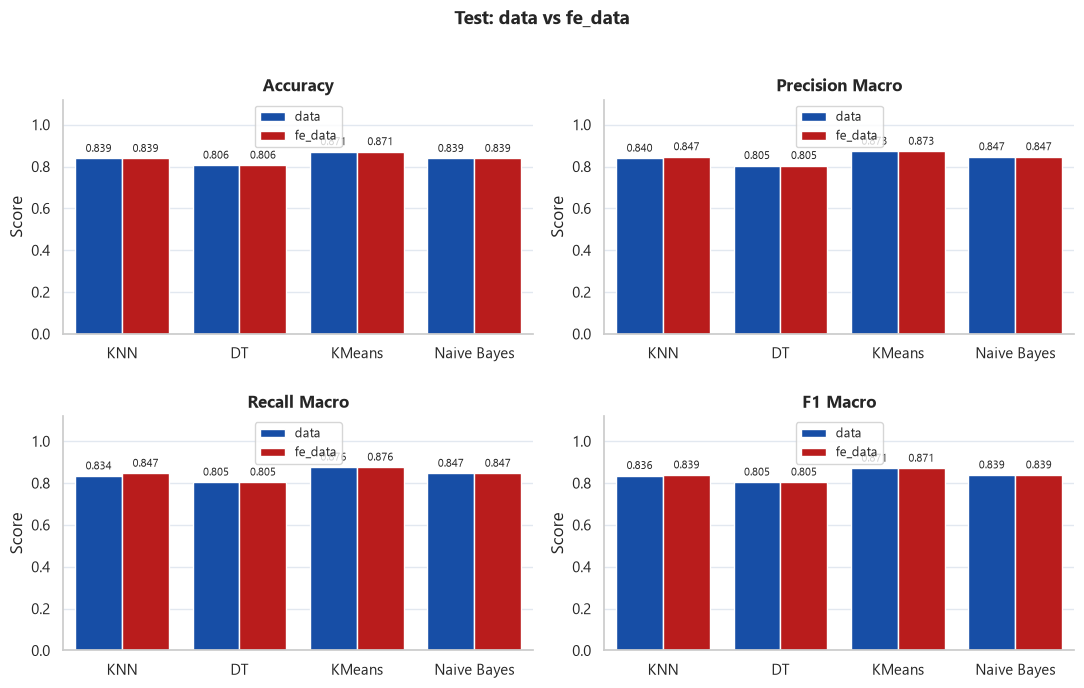

In [6]:
test_results = {}
test_frames = []
for dataset_name in DATASET_ORDER:
    parts = datasets[dataset_name]
    result = evaluate_test(fitted_models[dataset_name], parts["X_test"],
                           parts["y_test"], dataset=dataset_name)
    test_results[dataset_name] = result
    test_frames.append(result[0])
test_metrics = pd.concat(test_frames, ignore_index=True)
display(test_metrics.round(4))
plot_metric_comparison(test_metrics, "Test: data vs fe_data")


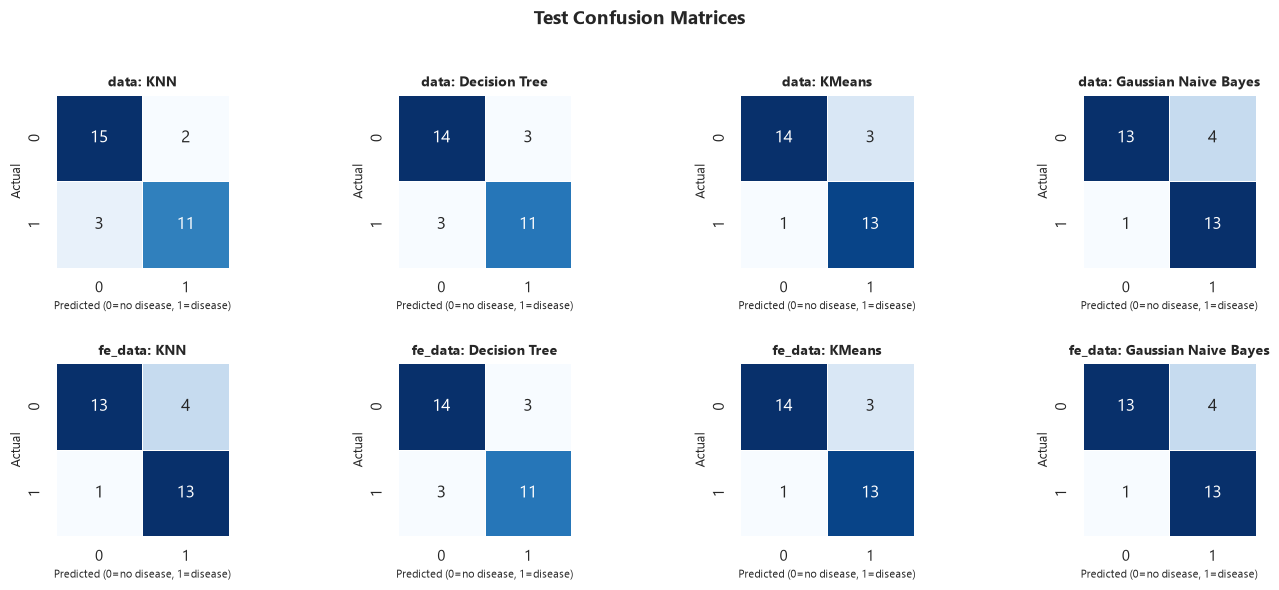

dataset                       data  fe_data  fe_minus_data
split model                                               
test  Decision Tree         0.8046   0.8046         0.0000
      Gaussian Naive Bayes  0.8387   0.8387         0.0000
      KMeans                0.8708   0.8708         0.0000
      KNN                   0.8360   0.8387         0.0027
val   Decision Tree         0.9330   0.9330         0.0000
      Gaussian Naive Bayes  0.8999   0.8999         0.0000
      KMeans                0.6970   0.7964         0.0994
      KNN                   0.8999   0.8999         0.0000

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for row, dataset_name in enumerate(DATASET_ORDER):
    for col, model_name in enumerate(MODEL_ORDER):
        matrix = test_results[dataset_name][1][model_name]
        ax = axes[row, col]
        sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                    square=True, linewidths=0.5, ax=ax)
        ax.set_title(f"{dataset_name}: {model_name}", fontsize=10)
        ax.set_xlabel("Predicted (0=no disease, 1=disease)", fontsize=8)
        ax.set_ylabel("Actual", fontsize=9)
fig.suptitle("Test Confusion Matrices", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=2)
plt.show()

all_metrics = pd.concat([val_metrics, test_metrics], ignore_index=True)
f1_comparison = all_metrics.pivot(index=["split", "model"], columns="dataset", values="f1_macro")
f1_comparison["fe_minus_data"] = f1_comparison["fe_data"] - f1_comparison["data"]
display(f1_comparison.round(4))


In [8]:
# Match the reference stacking, independently of standalone CV parameters.
# Three base models -> out-of-fold probabilities -> final KNN(k=5).
stacking_models = {}
stacking_results = {}
stacking_frames = []
stacking_config = []
for dataset_name in DATASET_ORDER:
    parts = datasets[dataset_name]
    stacking = fit_stacking_ensemble(
        parts["X_train"], parts["y_train"],
        knn_k=5, tree_depth=None, final_k=5, n_splits=5, random_state=42,
    )
    stacking_models[dataset_name] = stacking
    stacking_config.append({
        "dataset": dataset_name, "base_knn_k": 5,
        "base_dt_depth": "None (unlimited)", "final_knn_k": 5,
        "stacking_folds": 5, "shuffle": False,
    })
    stacking_results[dataset_name] = {}
    for split, evaluator in [("val", evaluate_val), ("test", evaluate_test)]:
        result = evaluator(
            {"Stacking (KNN final)": stacking},
            parts[f"X_{split}"], parts[f"y_{split}"], dataset=dataset_name,
        )
        stacking_results[dataset_name][split] = result
        stacking_frames.append(result[0])

stacking_metrics = pd.concat(stacking_frames, ignore_index=True)
display(pd.DataFrame(stacking_config))
display(stacking_metrics.round(4))


,dataset,base_knn_k,base_dt_depth,final_knn_k,stacking_folds,shuffle
0,data,5,None (unlimited),5,5,False
1,fe_data,5,None (unlimited),5,5,False


,dataset,split,model,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro
0,data,val,Stacking (KNN final),0.8667,0.8661,0.8661,0.8661,0.8661
1,data,test,Stacking (KNN final),0.8387,0.8466,0.8466,0.8466,0.8387
2,fe_data,val,Stacking (KNN final),0.9333,0.9375,0.9375,0.9375,0.9333
3,fe_data,test,Stacking (KNN final),0.9032,0.9118,0.9118,0.9118,0.9032
